# Sedap or Overhyped? English–Malay Code-Switching and Sentiment in Ayam Gepuk Reviews.

## Install packages and define path

In [36]:
%pip install pandas openpyxl matplotlib

Note: you may need to restart the kernel to use updated packages.


In [59]:
from pathlib import Path
from collections import Counter
import re

import pandas as pd
import matplotlib.pyplot as plt

# Assumes the notebook runs from the notebooks folder.
PROJECT_DIR = Path.cwd().parent
INPUT_FILE = PROJECT_DIR / "Data" / "CPC 353 Dataset.xlsx"

TABLE_DIR = PROJECT_DIR / "Outputs" / "Tables"
FIGURE_DIR = PROJECT_DIR / "Outputs" / "Figures"

TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

assert INPUT_FILE.exists(), f"File not found: {INPUT_FILE}"

## Load the annotated dataset

In [38]:
df = pd.read_excel(
    INPUT_FILE,
    sheet_name="Self-Collected Data",
    header=3,
    usecols="A:M",
    dtype={"Review ID": "string"},
    keep_default_na=False,
)

# Track original sheet rows before selecting populated records.
df.insert(0, "source_row", range(5, len(df) + 5))

# Ignore unused worksheet rows, while preserving all populated records.
data_columns = df.drop(columns="source_row")

populated = data_columns.apply(
    lambda column: (
        column.notna()
        & column.astype("string").str.strip().ne("").fillna(False)
    )
).any(axis=1)


df = df.loc[populated].copy()

df.head()

,source_row,Review ID,Data Origin,Product Category,Restaurant Location,Source Platform,Source URL,Rating (1-5),Review Date,Review Text,Language Classification,Code-Switching Type,Notes / Annotator Comments,Sentiment
0,5,REV-001,Self-Collected (Real),Ayam Gepuk,Ayam Gepuk Macet Chow Kit,Google Reviews,https://maps.app.goo.gl/BohQVGqPMgvuPLD57?g_st=aw,5,2026-05-28,Best ayam gepuk in Chow Kit area. Large portio...,Code-switched,Intra-sentential,"“Large portion dan sedap"" and ""Sambal also cuk...",Positive
1,6,REV-002,Self-Collected (Real),Ayam Gepuk,Ayam Gepuk Macet Chow Kit,Google Reviews,https://maps.app.goo.gl/BohQVGqPMgvuPLD57?g_st=aw,5,2026-02-04,Dont know where to eat and just google so we f...,Code-switched,Intra-sentential,"""The Kobis Goreng alsoo sedap!"" combines Engli...",Positive
2,7,REV-003,Self-Collected (Real),Ayam Gepuk,Ayam Gepuk Macet Chow Kit,Google Reviews,https://maps.app.goo.gl/BohQVGqPMgvuPLD57?g_st=aw,5,2025-11-26,I’m not the type who usually will leave a revi...,Code-switched,Intra-sentential,"""they will come to your table & bawa your plat...",Positive
3,8,REV-004,Self-Collected (Real),Ayam Gepuk,Ayam Gepuk Macet Chow Kit,Google Reviews,https://maps.app.goo.gl/BohQVGqPMgvuPLD57?g_st=aw,5,2026-05-18,Finally found ayam gepuk that really makes me ...,Code-switched,Intra-sentential,"“Ayam sedap, sambals the best, but paling best...",Positive
4,9,REV-005,Self-Collected (Real),Ayam Gepuk,Ayam Gepuk Macet Chow Kit,Google Reviews,https://maps.app.goo.gl/BohQVGqPMgvuPLD57?g_st=aw,5,2025-08-23,"Service bagus, portion besar and value for mon...",Code-switched,Intra-sentential,"“Service bagus, portion besar and value for mo...",Positive


In [39]:
# Confirmed expected columns exist

required_columns = [
    "Review ID",
    "Restaurant Location",
    "Review Text",
    "Language Classification",
    "Code-Switching Type",
    "Notes / Annotator Comments",
    "Sentiment",
]

missing_columns = set(required_columns) - set(df.columns)

assert not missing_columns, (
    f"Missing expected columns: {sorted(missing_columns)}"
)

## Check data quality

### Identify issues without changing records

In [61]:
issues = []

for column in required_columns:
    blank = (df[column].isna() | df[column].astype("string").str.strip().eq("").fillna(False))

    for _, row in df.loc[blank].iterrows():
        issues.append({
            "source_row": row["source_row"],
            "review_id": row["Review ID"],
            "field": column,
            "issue": "Missing or empty value",
        })

for column in ["Review ID", "Review Text"]:
    duplicated = df[column].notna() & df[column].duplicated(keep=False)

    for _, row in df.loc[duplicated].iterrows():
        issues.append({
            "source_row": row["source_row"],
            "review_id": row["Review ID"],
            "field": column,
            "issue": "Exact duplicate; review before taking action",
        })

issue_log = pd.DataFrame(
    issues,
    columns=["source_row", "review_id", "field", "issue"],
)

issue_log.to_csv(
    TABLE_DIR / "data_review_flags.csv",
    index=False,
    encoding="utf-8-sig",
)

display(issue_log)

# IDs and text are necessary for reliable extraction.
if (
    df["Review ID"].astype("string").str.strip().eq("").any()
    or df["Review ID"].duplicated().any()
):
    raise ValueError("Review missing or duplicate IDs before continuing.")

if df["Review Text"].astype("string").str.strip().eq("").any():
    raise ValueError("Review empty texts before continuing.")

,source_row,review_id,field,issue


In [41]:
# Display the actual count
print("Total reviews:", len(df), "\n")
print(df["Language Classification"].value_counts(dropna=False), "\n")
print(df["Code-Switching Type"].value_counts(dropna=False))

Total reviews: 197 

Language Classification
Code-switched    144
English           36
Malay             17
Name: count, dtype: int64 

Code-Switching Type
Intra-sentential    139
N/A                  53
Inter-sentential      5
Name: count, dtype: int64


## Calculate language and switching distribution

In [63]:
cs = df.loc[df["Language Classification"].eq("Code-switched")].copy()

assert len(cs) > 0, "No code-switched reviews were found."

# Analysis for language type
language_summary = (
    df["Language Classification"]
    .value_counts()
    .rename_axis("language")
    .reset_index(name="review_count")
)

language_summary["percentage"] = (language_summary["review_count"] / len(df) * 100).round(2)

# Analysis for code-switching type
switching_summary = (
    cs["Code-Switching Type"]
    .value_counts()
    .reindex(["Intra-sentential", "Inter-sentential", "Tag Switching"], fill_value=0,)
    .rename_axis("primary_switching_type")
    .reset_index(name="review_count")
)

switching_summary["percentage"] = (switching_summary["review_count"] / len(cs) * 100).round(2)

display(language_summary)
display(switching_summary)

,language,review_count,percentage
0,Code-switched,144,73.10
1,English,36,18.27
2,Malay,17,8.63


,primary_switching_type,review_count,percentage
0,Intra-sentential,139,96.53
1,Inter-sentential,5,3.47
2,Tag Switching,0,0.00


## Define searches and generate KWIC

### Search terms

In [64]:
search_terms = {
    "sedap": ["sedap", "sedapp", "sedappp", "sedapppppp"],
    "pedas": ["pedas"],
    "service": ["service"],
    "tapi": ["tapi"],
    "but": ["but"],
    "repeat": ["repeat"],
    "portion": ["portion"],
    "refill": ["refill"],
    "juicy": ["juicy"],
    "worth": ["worth"],
}

search_register = pd.DataFrame([
    {
        "search_term": term,
        "included_forms": " | ".join(forms),
        "case_sensitive": False,
        "context_tokens_each_side": 5,
    }
    for term, forms in search_terms.items()
])

display(search_register)

,search_term,included_forms,case_sensitive,context_tokens_each_side
0,sedap,sedap | sedapp | sedappp | sedapppppp,False,5
1,pedas,pedas,False,5
2,service,service,False,5
3,tapi,tapi,False,5
4,but,but,False,5
5,repeat,repeat,False,5
6,portion,portion,False,5
7,refill,refill,False,5
8,juicy,juicy,False,5
9,worth,worth,False,5


### Extraction function

In [45]:
# KWIC function
def extract_kwic(text, pattern, window=5):
    """Return source-preserving context for each regex match."""
    tokens = list(re.finditer(r"\S+", text))

    for match in pattern.finditer(text):
        overlapping = [
            i for i, token in enumerate(tokens)
            if token.start() < match.end()
            and token.end() > match.start()
        ]

        if not overlapping:
            continue

        first_token = overlapping[0]
        last_token = overlapping[-1]

        left_index = max(0, first_token - window)
        right_index = min(len(tokens) - 1, last_token + window)

        context_start = tokens[left_index].start()
        context_end = tokens[right_index].end()

        yield {
            "match_start": match.start(),
            "match_end": match.end(),
            "left_context": text[context_start:match.start()],
            "matched_form": match.group(),
            "right_context": text[match.end():context_end],
        }

### Generate the table

In [46]:
# Result of KWIC
kwic_rows = []

for _, review in cs.iterrows():
    text = review["Review Text"]

    if not isinstance(text, str) or not text.strip():
        continue

    for term, forms in search_terms.items():
        alternatives = "|".join(
            re.escape(form)
            for form in sorted(set(forms), key=len, reverse=True)
        )

        pattern = re.compile(
            rf"(?<!\w)(?:{alternatives})(?!\w)",
            flags=re.IGNORECASE,
        )

        for occurrence in extract_kwic(text, pattern):
            kwic_rows.append({
                "review_id": review["Review ID"],
                "source_row": review["source_row"],
                "search_term": term,
                **occurrence,
                "primary_switching_type":
                    review["Code-Switching Type"],
                "restaurant": review["Restaurant Location"],
                "sentiment": review["Sentiment"],
                "existing_notes":
                    review["Notes / Annotator Comments"],
                "full_review": text,
            })

kwic = pd.DataFrame(kwic_rows)

kwic.insert(
    0,
    "hit_id",
    [
        f"{row.review_id}:{row.search_term}:{row.match_start}"
        for row in kwic.itertuples()
    ],
)

kwic.head(10)

,hit_id,review_id,source_row,search_term,match_start,match_end,left_context,matched_form,right_context,primary_switching_type,restaurant,sentiment,existing_notes,full_review
0,REV-001:sedap:52,REV-001,5,sedap,52,57,Kit area. Large portion dan,sedap,. Sambal also cukup pedas. Kobis,Intra-sentential,Ayam Gepuk Macet Chow Kit,Positive,"“Large portion dan sedap"" and ""Sambal also cuk...",Best ayam gepuk in Chow Kit area. Large portio...
1,REV-001:pedas:77,REV-001,5,pedas,77,82,dan sedap. Sambal also cukup,pedas,". Kobis goreng, tempe etc also",Intra-sentential,Ayam Gepuk Macet Chow Kit,Positive,"“Large portion dan sedap"" and ""Sambal also cuk...",Best ayam gepuk in Chow Kit area. Large portio...
2,REV-001:portion:40,REV-001,5,portion,40,47,in Chow Kit area. Large,portion,dan sedap. Sambal also cukup,Intra-sentential,Ayam Gepuk Macet Chow Kit,Positive,"“Large portion dan sedap"" and ""Sambal also cuk...",Best ayam gepuk in Chow Kit area. Large portio...
3,REV-002:sedap:903,REV-002,6,sedap,903,908,restaurant. The Kobis Goreng alsoo,sedap,"! Not bitter at all, still",Intra-sentential,Ayam Gepuk Macet Chow Kit,Positive,"""The Kobis Goreng alsoo sedap!"" combines Engli...",Dont know where to eat and just google so we f...
4,REV-002:but:618,REV-002,6,but,618,621,"itself to topup our food,",but,here the staff always by,Intra-sentential,Ayam Gepuk Macet Chow Kit,Positive,"""The Kobis Goreng alsoo sedap!"" combines Engli...",Dont know where to eat and just google so we f...
5,REV-002:repeat:974,REV-002,6,repeat,974,980,taste the sweetness. Will alwaysss,repeat,again and again heree!! Thank,Intra-sentential,Ayam Gepuk Macet Chow Kit,Positive,"""The Kobis Goreng alsoo sedap!"" combines Engli...",Dont know where to eat and just google so we f...
6,REV-002:portion:699,REV-002,6,portion,699,706,food here also very HUGE,PORTION,! Sambal very good &,Intra-sentential,Ayam Gepuk Macet Chow Kit,Positive,"""The Kobis Goreng alsoo sedap!"" combines Engli...",Dont know where to eat and just google so we f...
7,REV-002:refill:479,REV-002,6,refill,479,485,Kacang & Nasi is free,refill,which is we just call,Intra-sentential,Ayam Gepuk Macet Chow Kit,Positive,"""The Kobis Goreng alsoo sedap!"" combines Engli...",Dont know where to eat and just google so we f...
8,REV-002:refill:532,REV-002,6,refill,532,538,the staff and they will,refill,that for you !! Others,Intra-sentential,Ayam Gepuk Macet Chow Kit,Positive,"""The Kobis Goreng alsoo sedap!"" combines Engli...",Dont know where to eat and just google so we f...
9,REV-002:juicy:830,REV-002,6,juicy,830,835,"goes to the chicken, very",juicy,and big size compared to,Intra-sentential,Ayam Gepuk Macet Chow Kit,Positive,"""The Kobis Goreng alsoo sedap!"" combines Engli...",Dont know where to eat and just google so we f...


## Verify and summarise keyword results

In [65]:
assert kwic["hit_id"].is_unique

for row in kwic.itertuples():
    assert (
        row.full_review[row.match_start:row.match_end]
        == row.matched_form
    )

keyword_summary = (
    kwic.groupby("search_term")
    .agg(
        occurrences=("hit_id", "size"),
        distinct_reviews=("review_id", "nunique"),
    )
    .reset_index()
    .sort_values("distinct_reviews", ascending=False)
)

display(keyword_summary)

kwic.to_csv(
    TABLE_DIR / "kwic_all_hits.csv",
    index=False,
    encoding="utf-8-sig",
)

keyword_summary.to_csv(
    TABLE_DIR / "keyword_search_summary.csv",
    index=False,
)

search_register.to_csv(
    TABLE_DIR / "search_register.csv",
    index=False,
)

,search_term,occurrences,distinct_reviews
6,sedap,104,79
7,service,49,39
8,tapi,52,36
2,pedas,50,31
0,but,52,29
5,repeat,19,18
3,portion,15,12
4,refill,15,11
1,juicy,11,9
9,worth,6,6


## Create a small, prefilled review workbook

### Prepare selected evidence

In [67]:
SELECTED_REVIEW_FILE = TABLE_DIR / "selected_evidence_review.xlsx"

if df["Review ID"].duplicated().any():
    raise ValueError("Duplicate review IDs must be reviewed first.")

source = df.set_index("Review ID")

# Example of the review
evidence_specs = [
    (
        "E01", "REV-001", "Intra-sentential",
        "Large portion dan sedap.",
        "English phrase + Malay evaluation",
        "Evaluation",
        "The English phrase 'Large portion' is followed by Malay "
        "'dan sedap', evaluating quantity and taste within one sentence."
    ),
    (
        "E02", "REV-005", "Intra-sentential",
        "Service bagus",
        "English phrase + Malay evaluation",
        "Evaluation",
        "The English noun 'Service' is followed by Malay 'bagus', "
        "giving a positive service evaluation."
    ),
    (
        "E03", "REV-008", "Intra-sentential",
        "First time try and tak menyesal sebab ayam gepuk sedap and service bagus.",
        "Alternating English and Malay clauses or phrases",
        "Evaluation",
        "English 'First time try and' introduces a Malay evaluation "
        "'tak menyesal sebab ...', followed by further mixed wording. "
        "The evidence goes beyond the food name."
    ),
    (
        "E04", "REV-018", "Intra-sentential",
        "Confirm repeat lagi!",
        "English return expression + Malay adverb",
        "Intention to return",
        "English 'Confirm repeat' combines with Malay 'lagi' to "
        "express an intention to return or repeat the experience."
    ),
    (
        "E05", "REV-022", "Intra-sentential",
        "Food ok , tapi time saya datang service agak lambat.",
        "Mixed evaluation linked by tapi",
        "Contrast",
        "The passage contrasts an acceptable food assessment with "
        "slow service. Malay 'tapi' links the contrast, with English "
        "'time' and 'service' embedded in the following wording."
    ),
    (
        "E06", "REV-175", "Intra-sentential",
        "Please lah tolong check betul2 before hntr kt driver grab.",
        "Alternating English and Malay clauses or phrases",
        "Request",
        "English 'Please', 'check', and 'before' occur with Malay "
        "'lah tolong', 'betul2', and abbreviated 'hntr kt'. "
        "The reviewer requests more careful order checking."
    ),
    (
        "E07", "REV-006", "Inter-sentential",
        None,
        "Malay evaluation followed by English return expression",
        "Evaluation and intention to return",
        "Under the team's punctuation rule, the Malay evaluation "
        "ending 'memang sedap ah' is separated from English "
        "'confirm repeat' by exclamation punctuation and an emoji."
    ),
    (
        "E08", "REV-016", "Inter-sentential",
        None,
        "Language alternation across line breaks",
        "Evaluation",
        "The Malay line 'Ayam gepuk yang lazat' is followed by "
        "'Services tip top' on a new line, then 'Sis puas hati'. "
        "This interpretation follows the existing annotation and "
        "the team's line-break convention."
    ),
    (
        "E09", "REV-054", "Inter-sentential",
        None,
        "Malay evaluation followed by English recommendation",
        "Evaluation and recommendation",
        "Malay 'sedap' and English 'recommend' are separated by "
        "exclamation punctuation. This counts as inter-sentential "
        "under the team's convention allowing short evaluative fragments."
    ),
    (
        "E10", "REV-130", "Inter-sentential",
        None,
        "Malay evaluation followed by English recommendation",
        "Evaluation and recommendation",
        "Malay 'SEDAP GILA!!!' is followed by English 'Must try ok?'. "
        "The recommendation follows the taste evaluation across "
        "a sentence boundary."
    ),
    (
        "E11", "REV-132", "Inter-sentential",
        None,
        "English evaluation followed by Malay evaluation",
        "Reiteration of evaluation",
        "English 'Taste very delicious.' is followed by Malay "
        "'Sangat sedap'. Both segments give a similar positive "
        "taste evaluation across a sentence boundary."
    ),
]

evidence_rows = []

for (
    evidence_id, review_id, observed_type, quote,
    pattern_group, function, interpretation
) in evidence_specs:

    if review_id not in source.index:
        raise ValueError(f"Missing source review: {review_id}")

    original = source.loc[review_id]

    # Use the complete review for the five inter-sentential cases.
    if quote is None:
        quote = original["Review Text"]

    if quote not in original["Review Text"]:
        raise ValueError(
            f"Draft quote does not exactly match {review_id}. "
            "Check the current dataset before proceeding."
        )

    evidence_rows.append({
        "evidence_id": evidence_id,
        "review_id": review_id,
        "source_row": original["source_row"],
        "evidence_quote": quote,
        "quote_occurrence": 1,
        "primary_switching_type": original["Code-Switching Type"],
        "observed_switch_type": observed_type,
        "pattern_group": pattern_group,
        "contextual_function": function,
        "draft_interpretation": interpretation,
        "sentiment": original["Sentiment"],
        "full_review": original["Review Text"],
        "existing_notes": original["Notes / Annotator Comments"],
        "review_decision": "",
        "reviewer_notes": "",
        "select_for_report": "",
    })

evidence_draft = pd.DataFrame(evidence_rows)

display(
    evidence_draft[
        ["evidence_id", "review_id", "evidence_quote",
         "draft_interpretation"]
    ]
)

,evidence_id,review_id,evidence_quote,draft_interpretation
0,E01,REV-001,Large portion dan sedap.,The English phrase 'Large portion' is followed...
1,E02,REV-005,Service bagus,The English noun 'Service' is followed by Mala...
2,E03,REV-008,First time try and tak menyesal sebab ayam gep...,English 'First time try and' introduces a Mala...
3,E04,REV-018,Confirm repeat lagi!,English 'Confirm repeat' combines with Malay '...
4,E05,REV-022,"Food ok , tapi time saya datang service agak l...",The passage contrasts an acceptable food asses...
5,E06,REV-175,Please lah tolong check betul2 before hntr kt ...,"English 'Please', 'check', and 'before' occur ..."
6,E07,REV-006,sedapppppp gileeeeee‼️ saya tiap minggu dengn ...,"Under the team's punctuation rule, the Malay e..."
7,E08,REV-016,Ayam gepuk yang lazat\nServices tip top\nSis p...,The Malay line 'Ayam gepuk yang lazat' is foll...
8,E09,REV-054,sedap！！recommend,Malay 'sedap' and English 'recommend' are sepa...
9,E10,REV-130,SEDAP GILA!!! Must try ok? All the way from sg...,Malay 'SEDAP GILA!!!' is followed by English '...


### Prepare small lexicon

In [68]:
lexicon_draft = pd.DataFrame([
    (
        "L01", "E01", "dan sedap", "Malay",
        "and tasty/delicious",
        "Adds a taste evaluation after an English phrase."
    ),
    (
        "L02", "E02", "Service bagus", "English–Malay",
        "good service",
        "Evaluates service using an English noun and Malay descriptor."
    ),
    (
        "L03", "E03", "tak menyesal", "Malay",
        "do not regret it",
        "Expresses satisfaction within a mixed-language review passage."
    ),
    (
        "L04", "E04", "Confirm repeat lagi", "English–Malay",
        "will definitely repeat or return again",
        "Expresses an intention to return."
    ),
    (
        "L05", "E05", "service agak lambat", "English–Malay",
        "service was rather slow",
        "Expresses a negative service assessment."
    ),
    (
        "L06", "E06", "check betul2", "English–Malay",
        "check properly or carefully",
        "Combines an English verb with an informal Malay expression; "
        "'betul2' represents 'betul-betul'."
    ),
], columns=[
    "lexicon_id",
    "evidence_id",
    "expression",
    "language_composition",
    "meaning_in_context",
    "usage_note",
])

lexicon_draft["review_decision"] = ""
lexicon_draft["reviewer_notes"] = ""

display(lexicon_draft)

,lexicon_id,evidence_id,expression,language_composition,meaning_in_context,usage_note,review_decision,reviewer_notes
0,L01,E01,dan sedap,Malay,and tasty/delicious,Adds a taste evaluation after an English phrase.,,
1,L02,E02,Service bagus,English–Malay,good service,Evaluates service using an English noun and Ma...,,
2,L03,E03,tak menyesal,Malay,do not regret it,Expresses satisfaction within a mixed-language...,,
3,L04,E04,Confirm repeat lagi,English–Malay,will definitely repeat or return again,Expresses an intention to return.,,
4,L05,E05,service agak lambat,English–Malay,service was rather slow,Expresses a negative service assessment.,,
5,L06,E06,check betul2,English–Malay,check properly or carefully,Combines an English verb with an informal Mala...,,


### Save without overwriting review

In [69]:
if SELECTED_REVIEW_FILE.exists():
    print("Existing review workbook preserved:")
else:
    with pd.ExcelWriter(
        SELECTED_REVIEW_FILE,
        engine="openpyxl",
    ) as writer:
        evidence_draft.to_excel(
            writer, sheet_name="Evidence", index=False
        )
        lexicon_draft.to_excel(
            writer, sheet_name="Lexicon", index=False
        )

    print("Created prefilled review workbook:")

print(SELECTED_REVIEW_FILE.resolve())

Created prefilled review workbook:
C:\Users\koay\Documents\KOAY KOAY FILES\USM\Year 3\CPC353\Assignment 1\CPC-354-Assignment-1\Outputs\Tables\selected_evidence_review.xlsx


## Read and validate the review workbook

In [71]:
evidence_review = pd.read_excel(
    SELECTED_REVIEW_FILE,
    sheet_name="Evidence",
    keep_default_na=False,
)

lexicon_review = pd.read_excel(
    SELECTED_REVIEW_FILE,
    sheet_name="Lexicon",
    keep_default_na=False,
)

required_evidence = set(evidence_draft.columns)
required_lexicon = set(lexicon_draft.columns)

if not required_evidence.issubset(evidence_review.columns):
    raise ValueError("Evidence tab is missing required columns.")

if not required_lexicon.issubset(lexicon_review.columns):
    raise ValueError("Lexicon tab is missing required columns.")

# Check that rows have not accidentally been lost or duplicated.
if (
    evidence_review["evidence_id"].duplicated().any()
    or set(evidence_review["evidence_id"])
       != set(evidence_draft["evidence_id"])
):
    raise ValueError("Evidence IDs do not match the prepared review form.")

if (
    lexicon_review["lexicon_id"].duplicated().any()
    or set(lexicon_review["lexicon_id"])
       != set(lexicon_draft["lexicon_id"])
):
    raise ValueError("Lexicon IDs do not match the prepared review form.")

for form in [evidence_review, lexicon_review]:
    form["review_decision"] = (
        form["review_decision"].astype(str).str.strip().str.title()
    )

    if not form["review_decision"].isin(
        ["", "Accept", "Reject"]
    ).all():
        raise ValueError("Use Accept, Reject, or blank for decisions.")

print("Evidence review:")
display(evidence_review["review_decision"].replace(
    "", "Pending"
).value_counts())

print("Lexicon review:")
display(lexicon_review["review_decision"].replace(
    "", "Pending"
).value_counts())

if (
    evidence_review["review_decision"].eq("").any()
    or lexicon_review["review_decision"].eq("").any()
):
    raise ValueError(
        "Some decisions are pending. Review the remaining rows, "
        "save the workbook, and rerun this cell."
    )

accepted = evidence_review.loc[
    evidence_review["review_decision"].eq("Accept")
].copy()

if accepted.empty:
    raise ValueError("No evidence has been accepted.")

expected_ids = evidence_draft.set_index("evidence_id")["review_id"]
allowed_types = {
    "Intra-sentential", "Inter-sentential", "Both", "Unclear"
}

validated_rows = []

for _, row in accepted.iterrows():
    evidence_id = row["evidence_id"]
    review_id = row["review_id"]

    if review_id != expected_ids.loc[evidence_id]:
        raise ValueError(f"Source review ID changed for {evidence_id}.")

    original = source.loc[review_id]
    text = original["Review Text"]
    quote = str(row["evidence_quote"])

    if not quote.strip():
        raise ValueError(f"Empty quotation: {evidence_id}")

    matches = list(re.finditer(re.escape(quote), text))

    try:
        number = float(str(row["quote_occurrence"]).strip() or "1")
        if not number.is_integer() or number < 1:
            raise ValueError
        occurrence = int(number)
    except (ValueError, OverflowError):
        raise ValueError(f"Invalid quote occurrence: {evidence_id}")

    if occurrence > len(matches):
        raise ValueError(
            f"Exact quotation not found for {evidence_id}."
        )

    for field in [
        "pattern_group",
        "contextual_function",
        "draft_interpretation",
    ]:
        if not str(row[field]).strip():
            raise ValueError(f"Missing {field}: {evidence_id}")

    if row["observed_switch_type"] not in allowed_types:
        raise ValueError(f"Invalid switching type: {evidence_id}")

    selected = str(row["select_for_report"]).strip().lower()
    if selected not in {"", "yes", "no"}:
        raise ValueError("Use Yes, No, or blank for select_for_report.")

    match = matches[occurrence - 1]

    validated_rows.append({
        "evidence_id": evidence_id,
        "review_id": review_id,
        "source_row": original["source_row"],
        "passage_id": f"{review_id}:{match.start()}:{match.end()}",
        "quote": quote,
        "primary_switching_type": original["Code-Switching Type"],
        "observed_switch_type": row["observed_switch_type"],
        "pattern_group": row["pattern_group"],
        "function": row["contextual_function"],
        "interpretation": row["draft_interpretation"],
        "sentiment": original["Sentiment"],
        "reviewer_notes": row["reviewer_notes"],
        "selected_for_report": selected == "yes",
    })

selected_evidence = pd.DataFrame(validated_rows)

if selected_evidence["passage_id"].duplicated().any():
    raise ValueError("Duplicate selected passages need review.")

display(selected_evidence)

Evidence review:


review_decision
Accept    11
Name: count, dtype: int64

Lexicon review:


review_decision
Accept    6
Name: count, dtype: int64

,evidence_id,review_id,source_row,passage_id,quote,primary_switching_type,observed_switch_type,pattern_group,function,interpretation,sentiment,reviewer_notes,selected_for_report
0,E01,REV-001,5,REV-001:34:58,Large portion dan sedap.,Intra-sentential,Intra-sentential,English phrase + Malay evaluation,Evaluation,The English phrase 'Large portion' is followed...,Positive,,True
1,E02,REV-005,9,REV-005:0:13,Service bagus,Intra-sentential,Intra-sentential,English phrase + Malay evaluation,Evaluation,The English noun 'Service' is followed by Mala...,Positive,,True
2,E03,REV-008,12,REV-008:56:129,First time try and tak menyesal sebab ayam gep...,Intra-sentential,Intra-sentential,Alternating English and Malay clauses or phrases,Evaluation,English 'First time try and' introduces a Mala...,Positive,,False
3,E04,REV-018,22,REV-018:283:303,Confirm repeat lagi!,Intra-sentential,Intra-sentential,English return expression + Malay adverb,Intention to return,English 'Confirm repeat' combines with Malay '...,Positive,,False
4,E05,REV-022,26,REV-022:0:52,"Food ok , tapi time saya datang service agak l...",Intra-sentential,Intra-sentential,Mixed evaluation linked by tapi,Contrast,The passage contrasts an acceptable food asses...,Positive,,True
5,E06,REV-175,179,REV-175:294:352,Please lah tolong check betul2 before hntr kt ...,Intra-sentential,Intra-sentential,Alternating English and Malay clauses or phrases,Request,"English 'Please', 'check', and 'before' occur ...",Negative,,True
6,E07,REV-006,10,REV-006:0:226,sedapppppp gileeeeee‼️ saya tiap minggu dengn ...,Inter-sentential,Inter-sentential,Malay evaluation followed by English return ex...,Evaluation and intention to return,"Under the team's punctuation rule, the Malay e...",Positive,,True
7,E08,REV-016,20,REV-016:0:52,Ayam gepuk yang lazat\nServices tip top\nSis p...,Inter-sentential,Inter-sentential,Language alternation across line breaks,Evaluation,The Malay line 'Ayam gepuk yang lazat' is foll...,Positive,,True
8,E09,REV-054,58,REV-054:0:16,sedap！！recommend,Inter-sentential,Inter-sentential,Malay evaluation followed by English recommend...,Evaluation and recommendation,Malay 'sedap' and English 'recommend' are sepa...,Positive,,False
9,E10,REV-130,134,REV-130:0:86,SEDAP GILA!!! Must try ok? All the way from sg...,Inter-sentential,Inter-sentential,Malay evaluation followed by English recommend...,Evaluation and recommendation,Malay 'SEDAP GILA!!!' is followed by English '...,Positive,,True


## Summarize the selected patterns

In [72]:
selected_pattern_summary = (
    selected_evidence.groupby("pattern_group")
    .agg(
        selected_passages=("passage_id", "nunique"),
        selected_reviews=("review_id", "nunique"),
        example_review_ids=(
            "review_id",
            lambda values: ", ".join(sorted(set(values))),
        ),
    )
    .reset_index()
    .sort_values("selected_reviews", ascending=False)
)

selected_pattern_summary["scope"] = (
    "Purposively selected evidence; not corpus-wide pattern frequency"
)

display(selected_pattern_summary)

selected_evidence.to_csv(
    TABLE_DIR / "selected_evidence_analysis.csv",
    index=False,
    encoding="utf-8-sig",
)

selected_pattern_summary.to_csv(
    TABLE_DIR / "selected_pattern_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

,pattern_group,selected_passages,selected_reviews,example_review_ids,scope
0,Alternating English and Malay clauses or phrases,2,2,"REV-008, REV-175",Purposively selected evidence; not corpus-wide...
2,English phrase + Malay evaluation,2,2,"REV-001, REV-005",Purposively selected evidence; not corpus-wide...
5,Malay evaluation followed by English recommend...,2,2,"REV-054, REV-130",Purposively selected evidence; not corpus-wide...
1,English evaluation followed by Malay evaluation,1,1,REV-132,Purposively selected evidence; not corpus-wide...
3,English return expression + Malay adverb,1,1,REV-018,Purposively selected evidence; not corpus-wide...
4,Language alternation across line breaks,1,1,REV-016,Purposively selected evidence; not corpus-wide...
6,Malay evaluation followed by English return ex...,1,1,REV-006,Purposively selected evidence; not corpus-wide...
7,Mixed evaluation linked by tapi,1,1,REV-022,Purposively selected evidence; not corpus-wide...


## Produce the inter-sentential analysis

In [73]:
inter_case_ids = {"E07", "E08", "E09", "E10", "E11"}

inter_case_review = evidence_review.loc[
    evidence_review["evidence_id"].isin(inter_case_ids),
    [
        "evidence_id",
        "review_id",
        "review_decision",
        "reviewer_notes",
    ],
]

display(inter_case_review)

inter_analysis = selected_evidence.loc[
    selected_evidence["evidence_id"].isin(inter_case_ids),
    [
        "review_id",
        "quote",
        "primary_switching_type",
        "observed_switch_type",
        "function",
        "interpretation",
        "sentiment",
    ],
].copy()

inter_analysis.to_csv(
    TABLE_DIR / "inter_sentential_analysis.csv",
    index=False,
    encoding="utf-8-sig",
)

display(inter_analysis)

rejected_inter = inter_case_review.loc[
    inter_case_review["review_decision"].eq("Reject")
]

if not rejected_inter.empty:
    print(
        "Some draft interpretations were rejected. Their original "
        "dataset labels remain unchanged. Explain these cases separately."
    )

,evidence_id,review_id,review_decision,reviewer_notes
6,E07,REV-006,Accept,
7,E08,REV-016,Accept,
8,E09,REV-054,Accept,
9,E10,REV-130,Accept,
10,E11,REV-132,Accept,


,review_id,quote,primary_switching_type,observed_switch_type,function,interpretation,sentiment
6,REV-006,sedapppppp gileeeeee‼️ saya tiap minggu dengn ...,Inter-sentential,Inter-sentential,Evaluation and intention to return,"Under the team's punctuation rule, the Malay e...",Positive
7,REV-016,Ayam gepuk yang lazat\nServices tip top\nSis p...,Inter-sentential,Inter-sentential,Evaluation,The Malay line 'Ayam gepuk yang lazat' is foll...,Positive
8,REV-054,sedap！！recommend,Inter-sentential,Inter-sentential,Evaluation and recommendation,Malay 'sedap' and English 'recommend' are sepa...,Positive
9,REV-130,SEDAP GILA!!! Must try ok? All the way from sg...,Inter-sentential,Inter-sentential,Evaluation and recommendation,Malay 'SEDAP GILA!!!' is followed by English '...,Positive
10,REV-132,Taste very delicious. Sangat sedap,Inter-sentential,Inter-sentential,Reiteration of evaluation,English 'Taste very delicious.' is followed by...,Positive


## Export the reviewed bilingual lexicon

In [74]:
accepted_lexicon = lexicon_review.loc[
    lexicon_review["review_decision"].eq("Accept")
].copy()

evidence_lookup = selected_evidence.set_index("evidence_id")
lexicon_rows = []

for _, row in accepted_lexicon.iterrows():
    evidence_id = row["evidence_id"]

    if evidence_id not in evidence_lookup.index:
        raise ValueError(
            f"{row['lexicon_id']} cites evidence that was not accepted."
        )

    evidence = evidence_lookup.loc[evidence_id]
    expression = str(row["expression"])

    if not expression.strip() or expression not in evidence["quote"]:
        raise ValueError(
            f"Expression is not an exact part of its evidence: "
            f"{row['lexicon_id']}"
        )

    for field in [
        "language_composition",
        "meaning_in_context",
        "usage_note",
    ]:
        if not str(row[field]).strip():
            raise ValueError(
                f"Missing {field} in {row['lexicon_id']}"
            )

    lexicon_rows.append({
        "expression": expression,
        "language_composition": row["language_composition"],
        "meaning_in_context": row["meaning_in_context"],
        "usage_note": row["usage_note"],
        "example_review_id": evidence["review_id"],
        "example_quote": evidence["quote"],
        "reviewer_notes": row["reviewer_notes"],
    })

lexicon = pd.DataFrame(lexicon_rows, columns=[
    "expression",
    "language_composition",
    "meaning_in_context",
    "usage_note",
    "example_review_id",
    "example_quote",
    "reviewer_notes",
])

lexicon.to_csv(
    TABLE_DIR / "bilingual_lexicon.csv",
    index=False,
    encoding="utf-8-sig",
)

display(lexicon)

,expression,language_composition,meaning_in_context,usage_note,example_review_id,example_quote,reviewer_notes
0,dan sedap,Malay,and tasty/delicious,Adds a taste evaluation after an English phrase.,REV-001,Large portion dan sedap.,
1,Service bagus,English–Malay,good service,Evaluates service using an English noun and Ma...,REV-005,Service bagus,
2,tak menyesal,Malay,do not regret it,Expresses satisfaction within a mixed-language...,REV-008,First time try and tak menyesal sebab ayam gep...,
3,Confirm repeat lagi,English–Malay,will definitely repeat or return again,Expresses an intention to return.,REV-018,Confirm repeat lagi!,
4,service agak lambat,English–Malay,service was rather slow,Expresses a negative service assessment.,REV-022,"Food ok , tapi time saya datang service agak l...",
5,check betul2,English–Malay,check properly or carefully,Combines an English verb with an informal Mala...,REV-175,Please lah tolong check betul2 before hntr kt ...,


## Export quotations, distributions, and figure

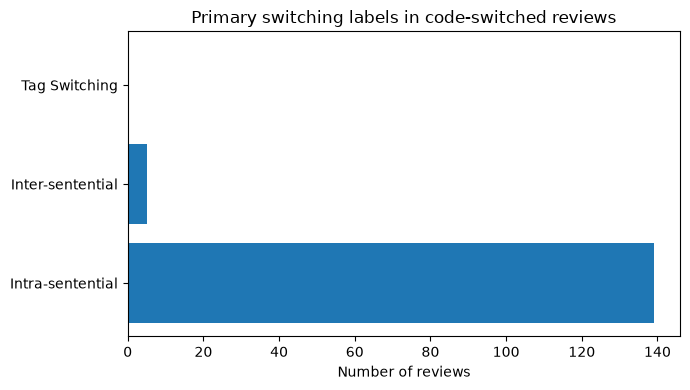

,review_id,quote,pattern_group,observed_switch_type,function,interpretation
0,REV-001,Large portion dan sedap.,English phrase + Malay evaluation,Intra-sentential,Evaluation,The English phrase 'Large portion' is followed...
1,REV-005,Service bagus,English phrase + Malay evaluation,Intra-sentential,Evaluation,The English noun 'Service' is followed by Mala...
4,REV-022,"Food ok , tapi time saya datang service agak l...",Mixed evaluation linked by tapi,Intra-sentential,Contrast,The passage contrasts an acceptable food asses...
5,REV-175,Please lah tolong check betul2 before hntr kt ...,Alternating English and Malay clauses or phrases,Intra-sentential,Request,"English 'Please', 'check', and 'before' occur ..."
6,REV-006,sedapppppp gileeeeee‼️ saya tiap minggu dengn ...,Malay evaluation followed by English return ex...,Inter-sentential,Evaluation and intention to return,"Under the team's punctuation rule, the Malay e..."
7,REV-016,Ayam gepuk yang lazat\nServices tip top\nSis p...,Language alternation across line breaks,Inter-sentential,Evaluation,The Malay line 'Ayam gepuk yang lazat' is foll...
9,REV-130,SEDAP GILA!!! Must try ok? All the way from sg...,Malay evaluation followed by English recommend...,Inter-sentential,Evaluation and recommendation,Malay 'SEDAP GILA!!!' is followed by English '...
10,REV-132,Taste very delicious. Sangat sedap,English evaluation followed by Malay evaluation,Inter-sentential,Reiteration of evaluation,English 'Taste very delicious.' is followed by...


In [77]:
# Export final table result
report_quotes = selected_evidence.loc[
    selected_evidence["selected_for_report"],
    [
        "review_id",
        "quote",
        "pattern_group",
        "observed_switch_type",
        "function",
        "interpretation",
    ],
].copy()

report_quotes.to_csv(
    TABLE_DIR / "selected_quotations.csv",
    index=False,
    encoding="utf-8-sig",
)

language_summary.to_csv(
    TABLE_DIR / "language_distribution.csv",
    index=False,
)

switching_summary.to_csv(
    TABLE_DIR / "primary_switching_distribution.csv",
    index=False,
)

keyword_summary.to_csv(
    TABLE_DIR / "keyword_search_summary.csv",
    index=False,
)

# Export final figure
fig, ax = plt.subplots(figsize=(7, 4))

ax.barh(
    switching_summary["primary_switching_type"],
    switching_summary["review_count"],
)

ax.set_xlabel("Number of reviews")
ax.set_title("Primary switching labels in code-switched reviews")

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "primary_switching_distribution.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
display(report_quotes)